In [1]:
from IPython.display import HTML

HTML('''<script>
code_show=true; 
function code_toggle() {
 if (code_show){
 $('div.input').hide();
 } else {
 $('div.input').show();
 }
 code_show = !code_show
} 
$( document ).ready(code_toggle);
</script>
<form action="javascript:code_toggle()"><input type="submit" value="Click here to toggle on/off the raw code."></form>''')



In [102]:


import numpy as np
import numpy.matlib
from numpy import pi
import pandas as pd
import xarray as xr
import netCDF4 as nc
from netCDF4 import Dataset, date2num
from scipy import stats
from scipy import ndimage



import matplotlib
import argparse
import time
import shutil
from math import pi
from shapely.geometry import Point,MultiPoint
from scipy.stats import pearsonr




#Plot packages
#matplotlib.use('Agg')
import matplotlib.pyplot as plt

import cmocean
from matplotlib.ticker import MaxNLocator
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib import colors
import cartopy.crs as ccrs
import cartopy.feature as cfeature


#system packages
import os, glob, sys, pprint, shlex,subprocess
from configparser import ConfigParser

config_object = ConfigParser()
config_object.read("config_base.ini")
config_info = config_object['CONFIG_BASE']
MODELS = config_info["MODELS"].split(',')
lon_min = int(config_info["lon_min"])
lon_max = int(config_info["lon_max"])
lat_min = int(config_info["lat_min"])
lat_max = int(config_info["lat_max"])
DATE1 = config_info["DATE_start"]
DATE2 = config_info["DATE_end"]
PROJECT = config_info["PROJECT"]
EXP_NAME = config_info["EXP_NAME"]
username = config_info["username"]
dir_work = config_info["dir_work"]
dir_in = config_info["dir_in"]
DRIFT_TIME = int(config_info['DRIFT_TIME'])
remote =  config_info['remote']

print("MODELS : ",MODELS)
print("Region : ",lon_min,", ",lon_max,", ",lat_min,", ",lat_max)
print("From : ",DATE1," to ",DATE2)

import datetime
import getpass
import sys
sys.path.insert(0, dir_in+"src/")
from Drift_Tools import ReturnUVlist, ExtractSurface, match_elements, StringRegion, DispDirAndLength,  SeparationDistance, TrajDistBetweenTimesteps, SepDistanceEachTimestep, LiuScore, shift360, DriftersInZoneInPeriod, coord2index

str_region = StringRegion(lon_min,lon_max,lat_min,lat_max)
dir_out=dir_work+"DRIFT/"+PROJECT+'/'+EXP_NAME+'/ZONE_'+str_region+'/'
from Drift_Tools import *
import datetime
username=getpass.getuser()
print('username: ',username)
matplotlib.use('Agg')


DD1=int(DATE1[:2])
MM1=int(DATE1[2:4])
YYYY1=int(DATE1[4:])
print(DD1,'-',MM1,'-',YYYY1)
date_start = datetime.date(YYYY1, MM1, DD1)
str_date1=date_start.strftime('%Y-%m-%d')
date_start_min1 = date_start-datetime.timedelta(days=1)

#reconstruct date_end
DD2=int(DATE2[:2])
MM2=int(DATE2[2:4])
YYYY2=int(DATE2[4:])
date_end = datetime.date(YYYY2, MM2, DD2)
str_date2=date_end.strftime('%Y-%m-%d')
date_end_plus1 = date_end+datetime.timedelta(days=1)





traj_files = []
for MODEL in MODELS:
    traj_files_int = []
    traj_files_int += sorted(glob.glob(dir_out+'EXP/'+MODEL+'/'+'Trajectories_'+MODEL+'_*at_SVPloc.zarr'))
    traj_files.append(traj_files_int)
traj_files = np.array(traj_files)





traj_lon = []
traj_lat = []
traj_time = []
for i in range(len(MODELS)):
    traj_lon_int = []
    traj_lat_int = []
    traj_time_int = []
    for file in traj_files[i]:
        ds = xr.open_dataset(file)
        traj_time_int.append(ds.time.values)
        traj_lon_int.append(ds.lon.values)
        traj_lat_int.append(ds.lat.values)
    traj_lon.append(traj_lon_int)
    traj_lat.append(traj_lat_int)
    traj_time.append(traj_time_int)
traj_lon = np.array(traj_lon)
traj_lat = np.array(traj_lat)
traj_time = np.array(traj_time)




#dir_in='/data/rd_exchange/pgouvenou/DATA/GlobalDriftingProgram//YEAR/'
dir_in = '/data/rd_exchange/svangennip/DATA/GlobalDriftingProgram/YEAR/'

fname_in='Drifters_'+str(YYYY1)+'.csv'
f_drifters_all=dir_in+fname_in
date_end_bis = datetime.date(YYYY2, MM2, DD2)+datetime.timedelta(days=DRIFT_TIME)
str_date3 = date_end_bis.strftime('%Y-%m-%d')
T_DRIFT = (date_end_bis -date_start).days
fout_driftersZone = 'Drifters_'+str_region+'_'+str_date1+'_'+str_date2+'.csv'
dir_drifters = dir_out+'/DRIFTERS/'


outfile2 = dir_drifters+fout_driftersZone



print('loading ',outfile2)
drifters_zone_traj = pd.read_csv(outfile2) #when unknown number of spaces separating columns
print(drifters_zone_traj.head(5))
print(drifters_zone_traj.dtypes)

    
nb_drifters_temp=len(pd.unique(drifters_zone_traj['id']))

#Sort drifter info in indiv. variables traj_lon, traj_lat, traj_id, etc...
if remote == "True":
    nb_points = T_DRIFT*24 +24   # hourly
else :
    nb_points = (T_DRIFT+1)*4 + 1    # hourly

traj_drifter_lon   = np.reshape(drifters_zone_traj.lon.values,(nb_drifters_temp, nb_points) )
traj_drifter_lat   = np.reshape(drifters_zone_traj.lat.values,(nb_drifters_temp, nb_points) )
traj_drifter_date = np.reshape(drifters_zone_traj.date.values,(nb_drifters_temp, nb_points) )
traj_drifter_time  = np.reshape(drifters_zone_traj.time.values,(nb_drifters_temp, nb_points) )
traj_drifter_id  = np.reshape(drifters_zone_traj.id.values,(nb_drifters_temp, nb_points) )



dir_plot = dir_out+'PLOT/'


if not os.path.exists(dir_plot):
    print('\ncreate folder : ', dir_plot)
    # Create directory where to store results:
    os.makedirs(dir_plot)





drifter_lon = np.zeros(traj_lon.shape)
drifter_lat = np.zeros(traj_lat.shape)


if remote == "True":
    drifter_lon[0,0,:,0] = traj_drifter_lon[:,:int(DRIFT_TIME)*24+24][:,0]
    drifter_lat[0,0,:,0] = traj_drifter_lat[:,:int(DRIFT_TIME)*24+24][:,0]
    
    drifter_lon[0,0,:,1:] = np.array([np.mean(traj_drifter_lon[:,1+i*6:12+i*6],axis = 1) for i in range (traj_lon.shape[-1]-1)]).T
    drifter_lat[0,0,:,1:] = np.array([np.mean(traj_drifter_lat[:,1+i*6:12+i*6],axis = 1) for i in range (traj_lat.shape[-1]-1)]).T




    for i in range (traj_lon.shape[0]):
        for j in range(traj_lon.shape[1]):
            drifter_lon[i,j,:,0] = traj_drifter_lon[:,j*24:j*24+int(DRIFT_TIME)*24+24][:,0]
            drifter_lat[i,j,:,0] = traj_drifter_lat[:,j*24:j*24+int(DRIFT_TIME)*24+24][:,0]
            
            drifter_lon[i,j,:,1:] = np.array([np.mean(traj_drifter_lon[:,j*24+1+i*6:j*24+12+i*6],axis = 1) for i in range (traj_lon.shape[-1]-1)]).T
            drifter_lat[i,j,:,1:] = np.array([np.mean(traj_drifter_lat[:,j*24+1+i*6:j*24+12+i*6],axis = 1) for i in range (traj_lat.shape[-1]-1)]).T
            



else : 
    drifter_lon[0,0] = traj_drifter_lon[:,:int(DRIFT_TIME)*4+1]
    drifter_lat[0,0] = traj_drifter_lat[:,:int(DRIFT_TIME)*4+1]





    for i in range (traj_lon.shape[0]):
        for j in range(traj_lon.shape[1]):
            drifter_lon[i,j] = traj_drifter_lon[:,j*4:int(DRIFT_TIME)*4+1+j*4]
            drifter_lat[i,j] = traj_drifter_lat[:,j*4:int(DRIFT_TIME)*4+1+j*4]




sep_dist = SeparationDistance(drifter_lon,drifter_lat,traj_lon,traj_lat)
liu_score = np.array([[LiuScore2(drifter_lon[i,j],drifter_lat[i,j],traj_lon[i,j],traj_lat[i,j]).T for j in range(traj_lon.shape[1])] for i in range (traj_lon.shape[0])])
skill_score = 1-liu_score
nans = np.unique(np.where(np.isnan(traj_lon))[2])
if len(nans)>0:
    traj_lon = np.delete(traj_lon,nans,axis = 2)
    traj_lat = np.delete(traj_lat,nans,axis = 2)
    drifter_lon = np.delete(drifter_lon,nans,axis = 2)
    drifter_lat = np.delete(drifter_lat,nans,axis = 2)

corr_lon = np.array([[[pearsonr(drifter_lon[i,j,k],traj_lon[i,j,k])[0] for k in range(traj_lon.shape[2])] for j in range(traj_lon.shape[1])] for i in range(traj_lon.shape[0])])
corr_lat = np.array([[[pearsonr(drifter_lat[i,j,k],traj_lat[i,j,k])[0] for k in range(traj_lat.shape[2])] for j in range(traj_lat.shape[1])] for i in range(traj_lat.shape[0])])



prop_sep_dist = np.count_nonzero(sep_dist[:,:,:,-1]<50 ,axis =(1,2) )/ (sep_dist.shape[1]*sep_dist.shape[2])
prop_skill_score = np.count_nonzero(skill_score[:,:,:,-1]>0 ,axis =(1,2) )/ (skill_score.shape[1]*skill_score.shape[2])
prop_corr_lon = np.count_nonzero(corr_lon>0.7 ,axis =(1,2) )/ (corr_lon.shape[1]*corr_lon.shape[2])
prop_corr_lat = np.count_nonzero(corr_lat>0.7 ,axis =(1,2) )/ (corr_lat.shape[1]*corr_lat.shape[2])






MODELS :  ['GLO12V4', 'GLOBC', 'PSY4V3R1']
Region :  -150 ,  -111 ,  16 ,  37
From :  15012019  to  15022019
username:  pgouvenou
15 - 1 - 2019


/home/pgouvenou/miniconda3/envs/env_validation_tools/lib/python3.11/site-packages/xarray/backends/plugins.py:159: RuntimeWarning: 'netcdf4' fails while guessing
  warnings.warn(f"{engine!r} fails while guessing", RuntimeWarning)
/home/pgouvenou/miniconda3/envs/env_validation_tools/lib/python3.11/site-packages/xarray/backends/plugins.py:159: RuntimeWarning: 'scipy' fails while guessing
  warnings.warn(f"{engine!r} fails while guessing", RuntimeWarning)
/home/pgouvenou/miniconda3/envs/env_validation_tools/lib/python3.11/site-packages/xarray/backends/plugins.py:159: RuntimeWarning: 'netcdf4' fails while guessing
  warnings.warn(f"{engine!r} fails while guessing", RuntimeWarning)
/home/pgouvenou/miniconda3/envs/env_validation_tools/lib/python3.11/site-packages/xarray/backends/plugins.py:159: RuntimeWarning: 'scipy' fails while guessing
  warnings.warn(f"{engine!r} fails while guessing", RuntimeWarning)
/home/pgouvenou/miniconda3/envs/env_validation_tools/lib/python3.11/site-packages/xarray

loading  /data/rd_exchange/pgouvenou/DRIFT/project/test/ZONE_150W111W-16N37N//DRIFTERS/Drifters_150W111W-16N37N_2019-01-15_2019-02-15.csv
   index               id        date      time     lat      lon       t  \
0      2  300234063840660  2019-01-15  12:00:00  22.084 -143.200  23.380   
1      3  300234063840660  2019-01-15  18:00:00  22.103 -143.220  23.582   
2      4  300234063840660  2019-01-16  00:00:00  22.106 -143.220  24.586   
3      5  300234063840660  2019-01-16  06:00:00  22.102 -143.213  23.734   
4      6  300234063840660  2019-01-16  12:00:00  22.088 -143.211  23.512   

       ve     vn   speed    varlat    varlon      vart  
0 -10.128  5.741  11.642  0.000003  0.000005  0.001684  
1  -4.819  5.418   7.251  0.000003  0.000005  0.001684  
2   1.759 -0.258   1.778  0.000003  0.000005  0.001684  
3   2.180 -4.537   5.034  0.000003  0.000005  0.001684  
4  -4.301 -4.584   6.286  0.000003  0.000005  0.001682  
index       int64
id          int64
date       object
time     

/home/pgouvenou/validation_tools_drifters/src/Drift_Tools.py:971: RuntimeWarning: invalid value encountered in divide
  liu_index.append(np.sum(di_SVP_MOD[:,:i], axis=1)/den)


In [106]:
matplotlib.use('Agg')
%matplotlib inline

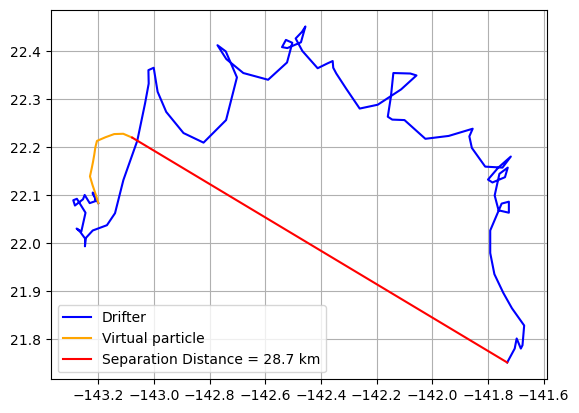

In [107]:
plt.plot(traj_drifter_lon.T[:,0][:-24*2+1],traj_drifter_lat.T[:,0][:-24*2+1],c='b',label = 'Drifter')
plt.plot(traj_lon[0,0,0],traj_lat[0,0,0],c = 'orange',label = 'Virtual particle')
plt.plot([traj_drifter_lon.T[:,0][:-24*2+1][-1],traj_lon[0,0,0][-1]],[traj_drifter_lat.T[:,0][:-24*2+1][-1],
                                                                      traj_lat[0,0,0][-1]],c = 'r',label = 'Separation Distance = '+str(round(sep_dist[0,0,0][-1],1)) +' km')
plt.grid()
plt.legend()
#plt.savefig('/home/pgouvenou/Documents/Figures_outil_validation_lagrangienne/separation_distance_diapo.png',dpi = 400)

/home/pgouvenou/miniconda3/envs/env_validation_tools/lib/python3.11/site-packages/cartopy/mpl/gridliner.py:451: UserWarning: The .xlabels_top attribute is deprecated. Please use .top_labels to toggle visibility instead.
  warnings.warn('The .xlabels_top attribute is deprecated. Please '
/home/pgouvenou/miniconda3/envs/env_validation_tools/lib/python3.11/site-packages/cartopy/mpl/gridliner.py:487: UserWarning: The .ylabels_right attribute is deprecated. Please use .right_labels to toggle visibility instead.
  warnings.warn('The .ylabels_right attribute is deprecated. Please '


(16.0, 37.0)

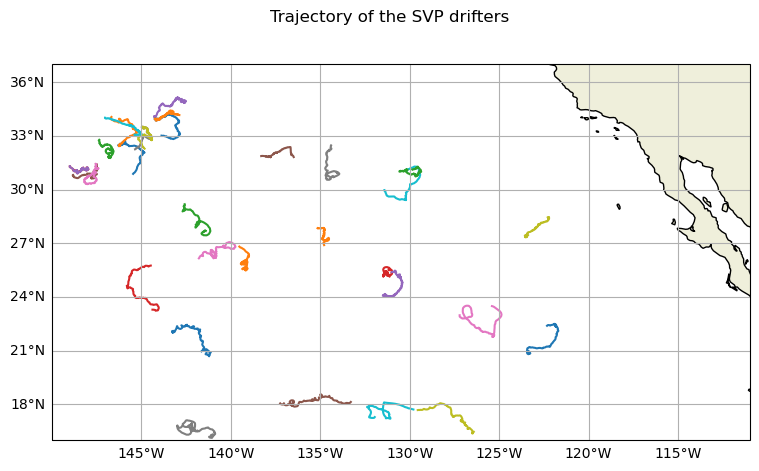

In [108]:
fig = plt.figure(figsize = (9,5))
axs=plt.axes(projection=ccrs.PlateCarree())
axs.coastlines()
axs.add_feature(cfeature.LAND)
gl = axs.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
gl.xlabels_top = False
gl.ylabels_right = False
fig.suptitle('Trajectory of the SVP drifters',fontsize = 12)

axs.plot(traj_drifter_lon.T,traj_drifter_lat.T,transform=ccrs.PlateCarree())
axs.set_xlim([lon_min,lon_max])
axs.set_ylim([lat_min,lat_max])

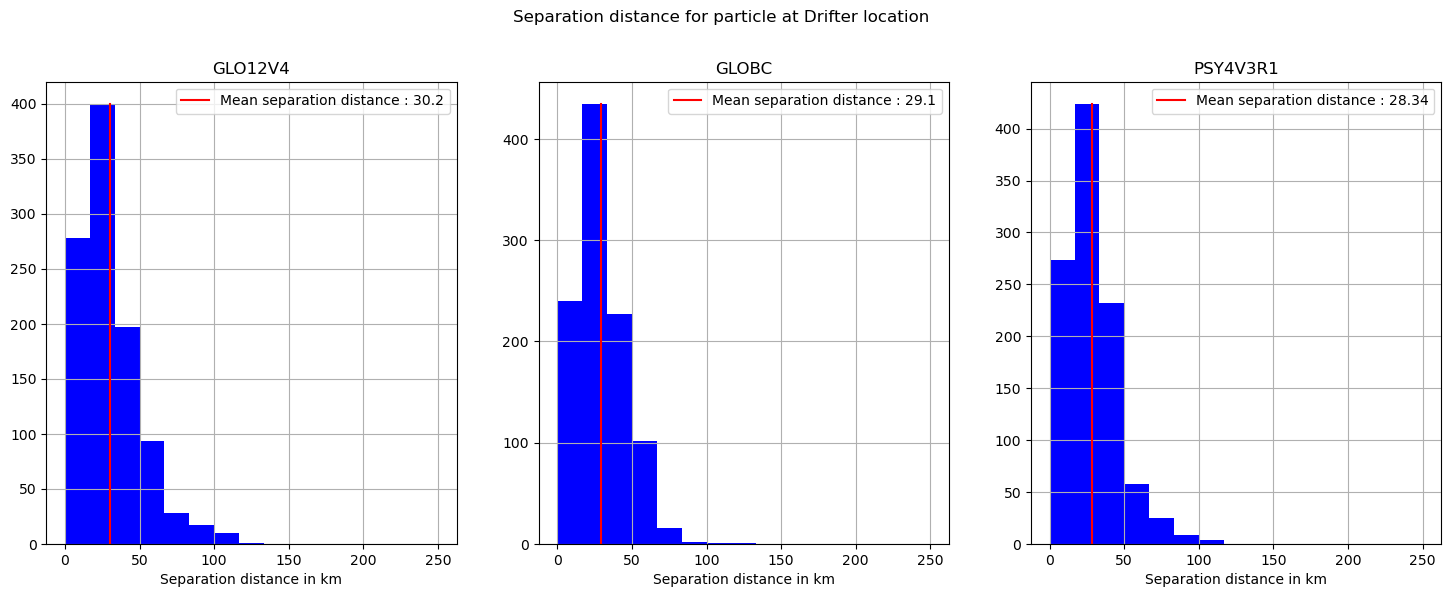

In [109]:
fig,axs = plt.subplots(nrows=1, ncols=len(MODELS),figsize = (6*len(MODELS),6))
fig.suptitle('Separation distance for particle at Drifter location',y = 1,x = 0.5,fontsize = 12)
n_sep = []
x_sep = []
if len(MODELS) == 1:
    n1, x1, _  = axs.hist(sep_dist[0].flatten(),bins =15,range=(0,250),color='b')
    axs.plot(np.nanmean(sep_dist[0,:,:,-1].flatten())*np.ones(2),[0,n1.max()],color= 'r',
                  label = 'Mean separation distance : ' + str(np.round(np.nanmean(sep_dist[0,:,:,-1].flatten()),2)))
    axs.set_title(MODELS[0])
    axs.set_xlabel('Separation distance in km')
    axs.legend()
    axs.grid()
    n_sep.append(n1)
    x_sep.append(x1)
    
else :     
    for i in range(len(MODELS)):
        n1, x1, _  = axs[i].hist(sep_dist[i,:,:,-1].flatten(),bins =15,range=(0,250),color='b')
        axs[i].plot(np.nanmean(sep_dist[i,:,:,-1].flatten())*np.ones(2),[0,n1.max()],color= 'r',
                      label = 'Mean separation distance : ' + str(np.round(np.nanmean(sep_dist[i,:,:,-1].flatten()),2)))
        axs[i].set_title(MODELS[i])
        axs[i].set_xlabel('Separation distance in km')
        axs[i].legend()
        axs[i].grid()

        n_sep.append(n1)
        x_sep.append(x1)
plt.savefig(dir_out+'PLOT/Separation_dis_hist.png',dpi = 400)

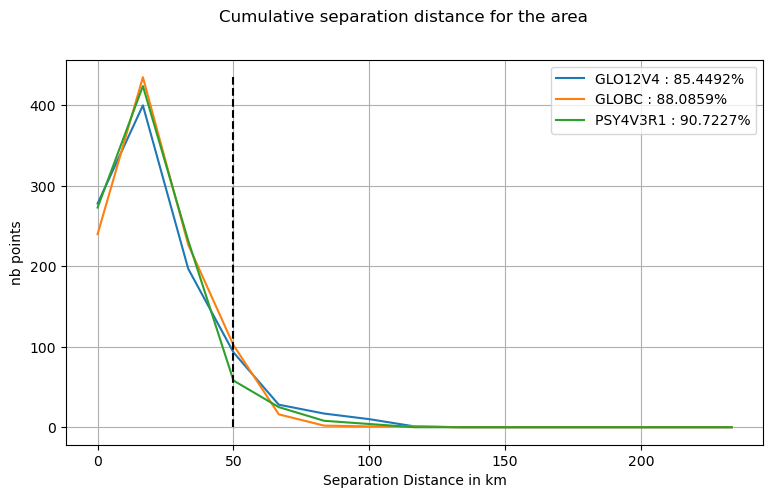

In [110]:
fig,axs = plt.subplots(nrows=1, ncols=1,figsize = (9,5))
fig.suptitle('Cumulative separation distance for the area',fontsize = 12)
for i in range (len(MODELS)):
    axs.plot(x_sep[i][:-1],n_sep[i],label =MODELS[i]+' : '+str(round(prop_sep_dist[i]*100,4)) + '%')


axs.plot([50,50],[0,np.max(n_sep)],'--',c='k')
axs.legend()
axs.set_xlabel('Separation Distance in km')
axs.set_ylabel('nb points')
plt.grid()
plt.savefig(dir_out+'PLOT/cumulative_separation.png',dpi = 400)

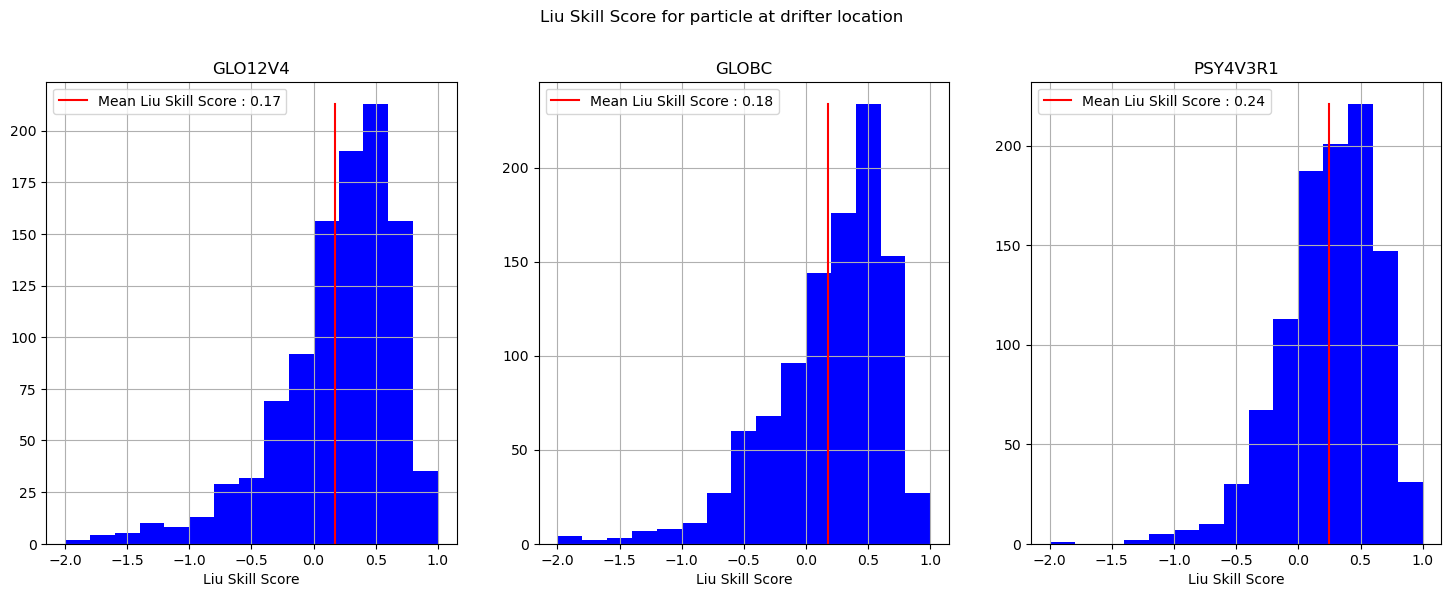

In [111]:
fig,axs = plt.subplots(nrows=1, ncols=len(MODELS),figsize = (6*len(MODELS),6))
fig.suptitle('Liu Skill Score for particle at drifter location',y = 1,x = 0.5,fontsize = 12)
n_liu = []
x_liu = []
if len(MODELS) == 1:
    n1, x1, _  = axs.hist(skill_score[0,:,:,-1].flatten(),bins =15,range=(-2,1),color='b')
    axs.plot(np.nanmean(skill_score[0,:,:,-1].flatten())*np.ones(2),[0,n1.max()],color= 'r',
                  label = 'Mean Liu Skill Score : ' + str(np.round(np.nanmean(skill_score[0,:,:,-1].flatten()),2)))
    axs.set_title(MODELS[0])
    axs.set_xlabel('Liu Skill Score')
    axs.legend()
    axs.grid()
    n_liu.append(n1)
    x_liu.append(x1)
    
else :     
    for i in range(len(MODELS)):
        n1, x1, _  = axs[i].hist(skill_score[i,:,:,-1].flatten(),bins =15,range=(-2,1),color='b')
        axs[i].plot(np.nanmean(skill_score[i,:,:,-1].flatten())*np.ones(2),[0,n1.max()],color= 'r',
                      label = 'Mean Liu Skill Score : ' + str(np.round(np.nanmean(skill_score[i,:,:,-1].flatten()),2)))
        axs[i].set_title(MODELS[i])
        axs[i].set_xlabel('Liu Skill Score')
        axs[i].legend()
        axs[i].grid()

        n_liu.append(n1)
        x_liu.append(x1)
plt.savefig(dir_out+'PLOT/Liu_hist.png',dpi = 400)

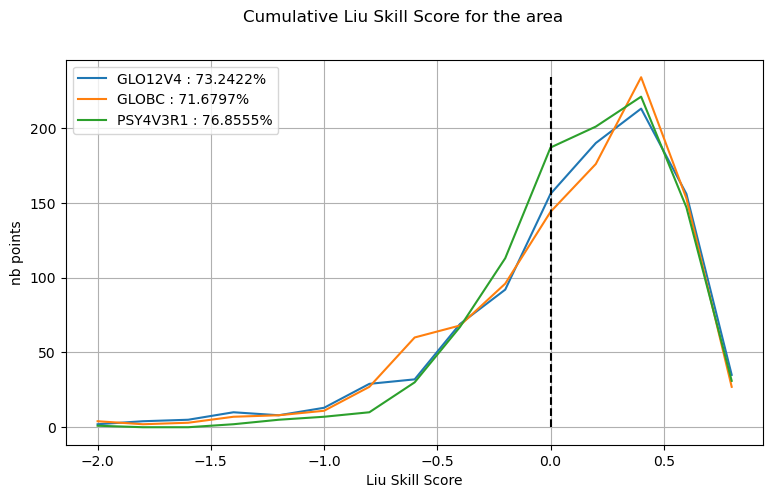

In [112]:
fig,axs = plt.subplots(nrows=1, ncols=1,figsize = (9,5))
fig.suptitle('Cumulative Liu Skill Score for the area',fontsize = 12)
for i in range (len(MODELS)):
    axs.plot(x_liu[i][:-1],n_liu[i],label =MODELS[i]+' : '+str(round(prop_skill_score[i]*100,4)) + '%')


axs.plot([0,0],[0,np.max(n_liu)],'--',c='k')
axs.legend()
axs.set_xlabel('Liu Skill Score')
axs.set_ylabel('nb points')
plt.grid()
plt.savefig(dir_out+'PLOT/Liu_cumulative.png',dpi = 400)

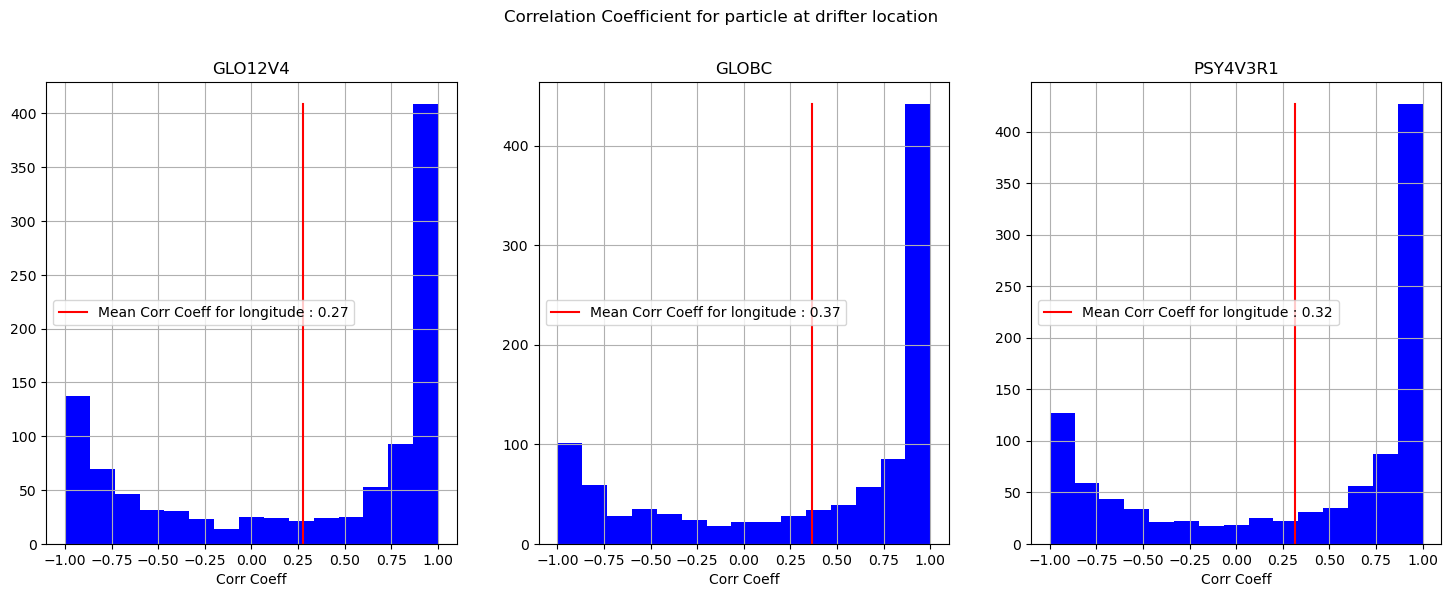

In [113]:
fig,axs = plt.subplots(nrows=1, ncols=len(MODELS),figsize = (6*len(MODELS),6))
fig.suptitle('Correlation Coefficient for particle at drifter location',y = 1,x = 0.5,fontsize = 12)
n_corr_lon = []
x_corr_lon = []
if len(MODELS) == 1:
    n1, x1, _  = axs.hist(corr_lon[0].flatten(),bins =15,range=(-1,1),color='b')
    axs.plot(np.nanmean(corr_lon[0].flatten())*np.ones(2),[0,n1.max()],color= 'r',
                  label = 'Mean Corr Coeff for longitude : ' + str(np.round(np.nanmean(corr_lon[0].flatten()),2)))
    axs.set_title(MODELS[0])
    axs.set_xlabel('Corr Coeff')
    axs.legend()
    axs.grid()
    n_corr_lon.append(n1)
    x_corr_lon.append(x1)
    
else :     
    for i in range(len(MODELS)):
        n1, x1, _  = axs[i].hist(corr_lon[i].flatten(),bins =15,range=(-1,1),color='b')
        axs[i].plot(np.nanmean(corr_lon[i].flatten())*np.ones(2),[0,n1.max()],color= 'r',
                      label = 'Mean Corr Coeff for longitude : ' + str(np.round(np.nanmean(corr_lon[i].flatten()),2)))
        axs[i].set_title(MODELS[i])
        axs[i].set_xlabel('Corr Coeff')
        axs[i].legend()
        axs[i].grid()

        n_corr_lon.append(n1)
        x_corr_lon.append(x1)
plt.savefig(dir_out+'PLOT/Corr_coef_lon_hist.png',dpi = 400)

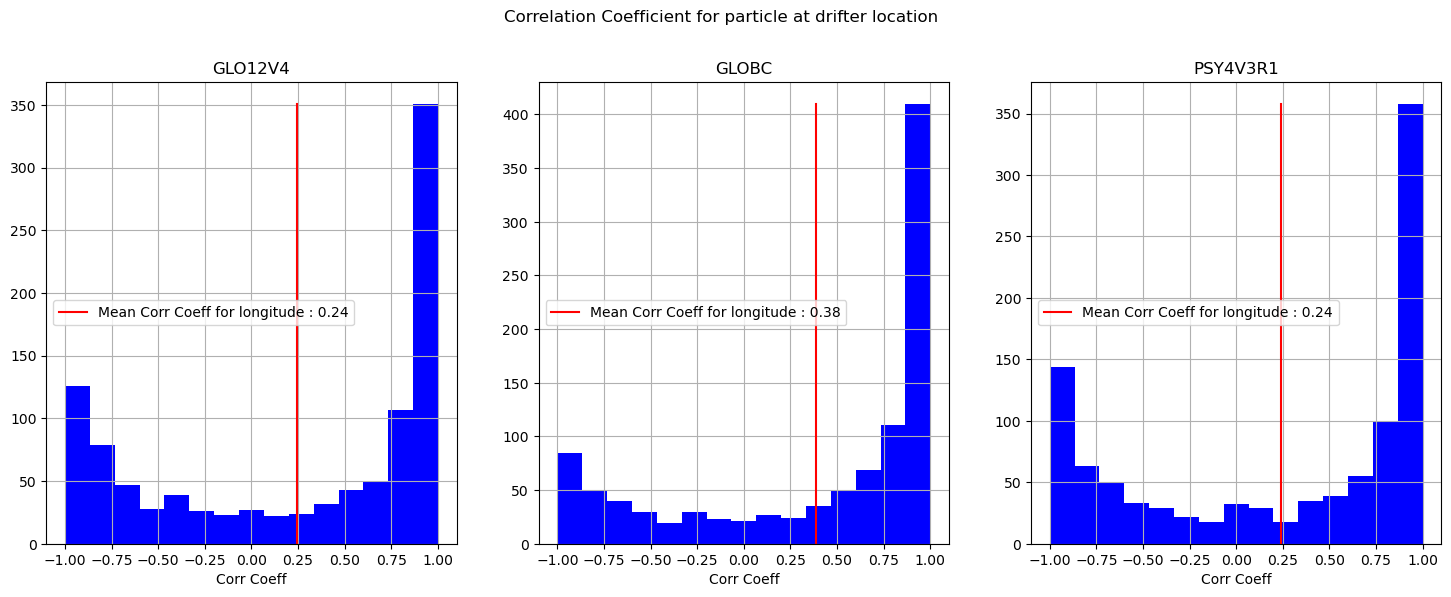

In [114]:
fig,axs = plt.subplots(nrows=1, ncols=len(MODELS),figsize = (6*len(MODELS),6))
fig.suptitle('Correlation Coefficient for particle at drifter location',y = 1,x = 0.5,fontsize = 12)
n_corr_lat = []
x_corr_lat = []
if len(MODELS) == 1:
    n1, x1, _  = axs.hist(corr_lat[0].flatten(),bins =15,range=(-1,1),color='b')
    axs.plot(np.nanmean(corr_lat[0].flatten())*np.ones(2),[0,n1.max()],color= 'r',
                  label = 'Mean Corr Coeff for latitude : ' + str(np.round(np.nanmean(corr_lat[0].flatten()),2)))
    axs.set_title(MODELS[0])
    axs.set_xlabel('Corr Coeff')
    axs.legend()
    axs.grid()
    n_corr_lat.append(n1)
    x_corr_lat.append(x1)
    
else :     
    for i in range(len(MODELS)):
        n1, x1, _  = axs[i].hist(corr_lat[i].flatten(),bins =15,range=(-1,1),color='b')
        axs[i].plot(np.nanmean(corr_lat[i].flatten())*np.ones(2),[0,n1.max()],color= 'r',
                      label = 'Mean Corr Coeff for longitude : ' + str(np.round(np.nanmean(corr_lat[i].flatten()),2)))
        axs[i].set_title(MODELS[i])
        axs[i].set_xlabel('Corr Coeff')
        axs[i].legend()
        axs[i].grid()

        n_corr_lat.append(n1)
        x_corr_lat.append(x1)
plt.savefig(dir_out+'PLOT/Corr_coef_lat_hist.png',dpi = 400)

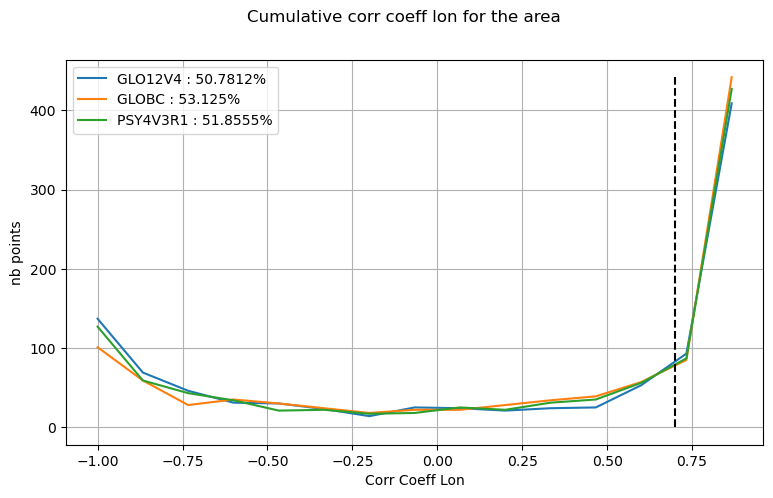

In [115]:
fig,axs = plt.subplots(nrows=1, ncols=1,figsize = (9,5))
fig.suptitle('Cumulative corr coeff lon for the area',fontsize = 12)
for i in range (len(MODELS)):
    axs.plot(x_corr_lon[i][:-1],n_corr_lon[i],label =MODELS[i]+' : '+str(round(prop_corr_lon[i]*100,4)) + '%')


axs.plot([0.7,0.7],[0,np.max(n_corr_lon)],'--',c='k')
axs.legend()
axs.set_xlabel('Corr Coeff Lon')
axs.set_ylabel('nb points')
plt.grid()
plt.savefig(dir_out+'PLOT/Corr_coef_lon_cumulative.png',dpi = 400)

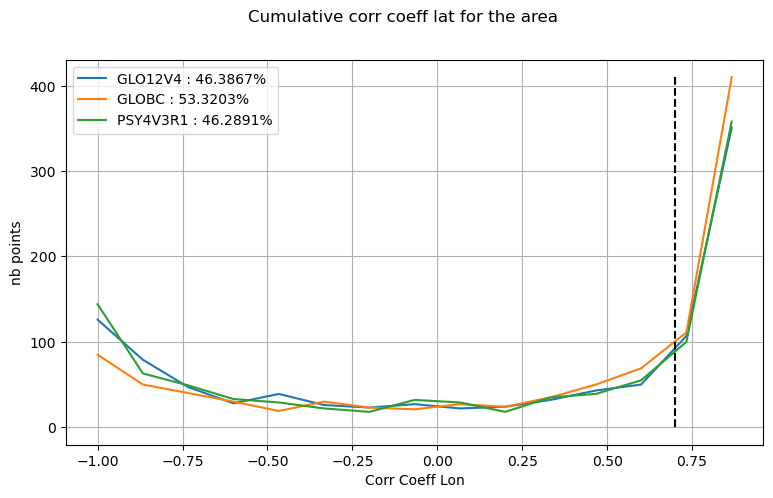

In [116]:
fig,axs = plt.subplots(nrows=1, ncols=1,figsize = (9,5))
fig.suptitle('Cumulative corr coeff lat for the area',fontsize = 12)
for i in range (len(MODELS)):
    axs.plot(x_corr_lat[i][:-1],n_corr_lat[i],label =MODELS[i]+' : '+str(round(prop_corr_lat[i]*100,4)) + '%')


axs.plot([0.7,0.7],[0,np.max(n_corr_lat)],'--',c='k')
axs.legend()
axs.set_xlabel('Corr Coeff Lon')
axs.set_ylabel('nb points')
plt.grid()
plt.savefig(dir_out+'PLOT/Corr_coef_lat_cumulative.png',dpi = 400)